# Questão 3

Aluna: Maria Eduarda Saldanha Alves

f(x) = e**(2-x**2) x (x + 1) **2

## Gráfico da função 

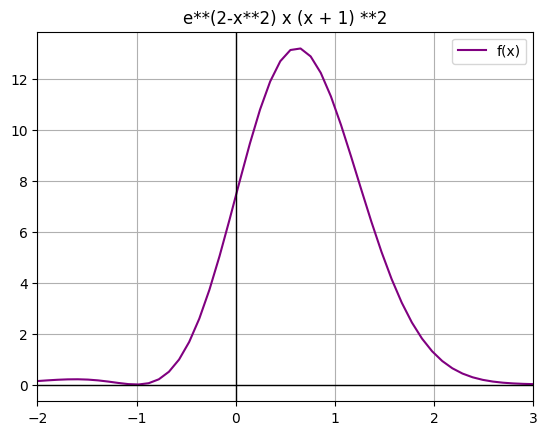

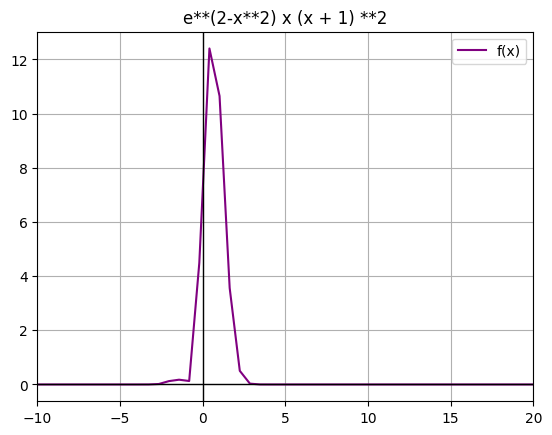

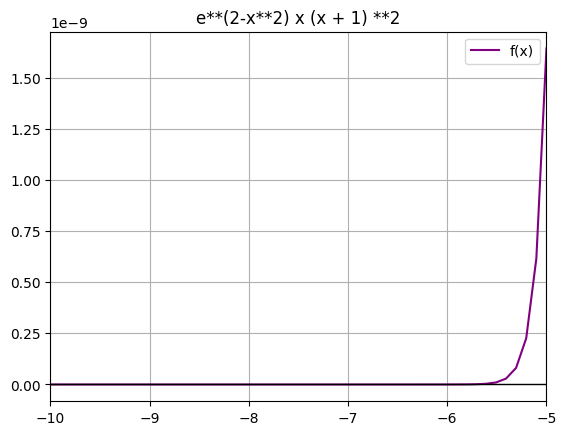

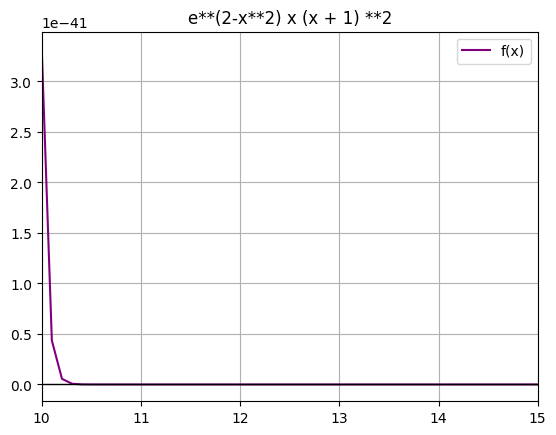

In [40]:
import matplotlib.pyplot as plt
import numpy as np

def f(x):
    return np.exp(2-x**2) * (x + 1)**2

def plot(a, b):
    intervalos = np.linspace(a, b)
    plt.plot(intervalos, f(intervalos), label = 'f(x)', color = 'purple')
    plt.axhline(0, color = 'black', linestyle = '-', linewidth = 1)
    plt.axvline(0, color = 'black', linestyle = '-', linewidth = 1)
    plt.xlim(a, b)
    plt.title('e**(2-x**2) x (x + 1) **2')
    plt.legend()
    plt.grid()
    plt.show()

plot(-2, 3)
plot(-10, 20)
plot(-10, -5)
plot(10, 15)

a função não tem apenas uma única raiz, há vários pontos em que intercepta o eixo x entre os intervalos [-10, -5] e [10, 15]

## Utilizando o método da Secante na função f(x)

In [41]:
import sympy as sy
import numpy as np
import pandas as pd

x_sy = sy.Symbol('x')
funcao_sy = sy.exp(2 - x_sy**2) * (x_sy + 1)**2
derivada = sy.diff(funcao_sy, x_sy)
print(f"Derivada de f(x): {derivada}")

def f_(x):
    return -2*x*(x + 1)**2*np.exp(2 - x**2) + (2*x + 2)*np.exp(2 - x**2)

segunda_derivada = sy.diff(derivada, x_sy)
print(f"Segunda derivada de f(x): {segunda_derivada}")

def f__(x):
    return 4*x**2*(x + 1)**2*np.exp(2 - x**2) - 4*x*(2*x + 2)*np.exp(2 - x**2) - 2*(x + 1)**2*np.exp(2 - x**2) + 2*np.exp(2 - x**2)

def secante(a, b, TOL, n):
    historico = []
    x_ = a
    x__ = b

    for k in range(1, n + 1):
        x = x_ - f_(x_) * ((x_ - x__) / (f(x_) - f(x__)))
        erro = abs((x - x_) / (max(x, 1)))

        historico.append({
            "k": k, "x": x, "f(x)": f(x), "erro": erro
        })

        if (f(x) == 0 or erro < TOL):
            break

        x_ = x
        x__ = x_

    df = pd.DataFrame(historico)
    print(df)

print("Intervalo de [-10, -5]")
secante(-10, -5, 1e-6, 100)
print("\n")
print("Intervalo de [10, 15]")
secante(10, 15, 1e-6, 100)

Derivada de f(x): -2*x*(x + 1)**2*exp(2 - x**2) + (2*x + 2)*exp(2 - x**2)
Segunda derivada de f(x): 4*x**2*(x + 1)**2*exp(2 - x**2) - 4*x*(2*x + 2)*exp(2 - x**2) - 2*(x + 1)**2*exp(2 - x**2) + 2*exp(2 - x**2)
Intervalo de [-10, -5]
   k     x          f(x)  erro
0  1 -10.0  2.226516e-41   0.0


Intervalo de [10, 15]
   k          x  f(x)       erro
0  1 -89.090909   0.0  99.090909


intervalo [-10, -5]:
O erro 0 é menor que 1e-6. Logo, a função converte na raiz -10.0.

intervalo [10, 15]:
O erro 0 é maior que 1e-6. Logo, a função diverge na raiz -89.090909.